# DiCo-NLI (SemEval-2027 Task 2), Track 1 — Assignment 1 (v2: 3 seeds)
**Task understanding → Data checks → Selective EDA → Classical baselines → Pretrained baselines → Evaluation → Error analysis**

Runs locally (Apple Silicon GPU via MPS, or CPU) or on Colab (CUDA). Everything is written to `results/`.

Helper modules (kept as `.py` so every section imports the same code):
- `src/data.py`: loads Track 1, writes official-format predictions, runs the organizers' scorer
- `src/features.py`: hand-crafted pair features, shared by the EDA and the feature baseline

**v2:** identical pipeline to v1, but each transformer is fine-tuned with 3 seeds (13, 42, 87) and results are reported as mean ± std. Outputs go to `results_v2/` so v1 results are untouched.

## 0. Setup and configuration

In [1]:
import json, random, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
%matplotlib inline

from src.data import load_split, write_predictions, score, headline, LABELS, REVERSE
from src.features import pair_features, pos_proportions, tokens, mtld

# ---- configuration ----
RUN_TRANSFORMERS = True                       # set False to skip fine-tuning (fast run)
# DeBERTa-v3 produces NaN losses on Apple's MPS backend, so on a Mac it is trained on CPU (slow).
# RoBERTa-base runs fine on MPS. On Colab (CUDA) all three run on the GPU.
MODELS = ["bert-base-uncased", "roberta-base"]   # add "microsoft/deberta-v3-base" on Colab
SEEDS = [13, 42, 87]                          # v2: 3 seeds -> mean ± std
CFG = dict(epochs=6, lr=3e-5, batch_size=16, max_len=64, warmup=0.1, weight_decay=0.01)
SEED = 42

OUT = Path("results_v2")
for p in ["predictions", "scores", "error_analysis"]:
    (OUT / p).mkdir(parents=True, exist_ok=True)

ORDER = ["FORWARD_ENTAILMENT", "BACKWARD_ENTAILMENT", "EQUIVALENCE", "NEGATIVE_OTHER"]
SHORT = {"FORWARD_ENTAILMENT": "FORWARD", "BACKWARD_ENTAILMENT": "BACKWARD",
         "EQUIVALENCE": "EQUIV", "NEGATIVE_OTHER": "NEG_OTHER"}
COLORS = {"FORWARD_ENTAILMENT": "#2a6fdb", "BACKWARD_ENTAILMENT": "#e07b24",
          "EQUIVALENCE": "#2b9e5e", "NEGATIVE_OTHER": "#8a8a8a"}
plt.rcParams.update({"figure.figsize": (8, 4.8), "axes.grid": True, "grid.alpha": 0.3})

## 1. Data
Official Track 1 split (train / dev). **No re-splitting:** the organizers group by `pair_id`, so a pair and its
flipped copy never cross the split. `trial_data` is not used because it overlaps train/dev.

In [2]:
train, dev = load_split("train"), load_split("dev")
train["split"], dev["split"] = "train", "dev"
df = pd.concat([train, dev], ignore_index=True)
df = pd.concat([df, pair_features(df)], axis=1)      # features used by EDA and baselines
print(len(train), "train rows |", len(dev), "dev rows")
df[["instance_id", "text1", "text2", "label"]].head(6)

3042 train rows | 660 dev rows


,instance_id,text1,text2,label
0,dico_phrasis_0000001__en-en__flipped,Conservative opposition,Conservatives,FORWARD_ENTAILMENT
1,dico_phrasis_0000001__en-en__original,Conservatives,Conservative opposition,BACKWARD_ENTAILMENT
2,dico_phrasis_0000003__en-en__flipped,Japanese PM Shinzo Abe,Abe,FORWARD_ENTAILMENT
3,dico_phrasis_0000003__en-en__original,Abe,Japanese PM Shinzo Abe,BACKWARD_ENTAILMENT
4,dico_phrasis_0000005__en-en__flipped,ballistic missiles,missiles,FORWARD_ENTAILMENT
5,dico_phrasis_0000005__en-en__original,missiles,ballistic missiles,BACKWARD_ENTAILMENT


## 2. Dataset-level checks

In [3]:
log = []
def say(*a):
    line = " ".join(str(x) for x in a); print(line); log.append(line)

for name, d in [("train", train), ("dev", dev)]:
    say(f"{name}: {len(d)} instances, {d.pair_id.nunique()} source pairs")
say("pair_id overlap train/dev:", len(set(train.pair_id) & set(dev.pair_id)))
say("missing values:", int(df[["text1", "text2", "label"]].isna().sum().sum()))
say("empty texts:", int(((df.text1.str.strip() == "") | (df.text2.str.strip() == "")).sum()))
say("identical text1==text2:", int(df.identical.sum()))
one = (df.len1 == 1) | (df.len2 == 1)
say("1-word phrase on either side:", int(one.sum()), f"({one.mean():.1%})")
say("max phrase length (tokens):", int(max(df.len1.max(), df.len2.max())))
dup = df.duplicated(["text1", "text2"], keep=False)
say("duplicated (text1,text2) rows:", int(dup.sum()))
say("  duplicated with DIFFERENT labels:", int((df[dup].groupby(["text1", "text2"]).label.nunique() > 1).sum()), "pairs")
tr_pairs = set(zip(train.text1, train.text2))
say("dev rows whose exact (text1,text2) is also in train:", sum((a, b) in tr_pairs for a, b in zip(dev.text1, dev.text2)))
say("\nrows per pair_id by label (NEGATIVE_OTHER has no flipped copy):")
say(pd.crosstab(df.label, df.groupby("pair_id").pair_id.transform("size")).to_string())
say("\nlabel distribution (share of rows):")
say(pd.crosstab(df.label, df.split, normalize="columns").round(3).to_string())

train: 3042 instances, 1760 source pairs
dev: 660 instances, 383 source pairs
pair_id overlap train/dev: 0
missing values: 0
empty texts: 0
identical text1==text2: 0
1-word phrase on either side: 698 (18.9%)
max phrase length (tokens): 15
duplicated (text1,text2) rows: 116
  duplicated with DIFFERENT labels: 1 pairs
dev rows whose exact (text1,text2) is also in train: 7

rows per pair_id by label (NEGATIVE_OTHER has no flipped copy):
pair_id                1     2
label                         
BACKWARD_ENTAILMENT    0  1071
EQUIVALENCE            0   976
FORWARD_ENTAILMENT     0  1071
NEGATIVE_OTHER       584     0

label distribution (share of rows):
split                  dev  train
label                            
BACKWARD_ENTAILMENT  0.288  0.290
EQUIVALENCE          0.264  0.264
FORWARD_ENTAILMENT   0.288  0.290
NEGATIVE_OTHER       0.161  0.157


## 3. Selective EDA
Feature groups, each answering a question about the task:
1. **Label distribution:** is the task imbalanced?
2. **Length / signed length difference:** does "the longer phrase entails the shorter" act as a shortcut?
3. **Lexical overlap (Jaccard) and containment:** how much do labels depend on shared words?
4. **POS of non-shared words:** which kind of word makes one phrase more specific?
5. **Semantic similarity (frozen MiniLM):** do embeddings separate equivalence from unrelated pairs?
6. **Vocabulary (OOV, MTLD, Zipf):** how sparse is the lexical signal?

All figures are also written to **one PDF**: `results/eda_plots.pdf`.

In [4]:
say("\n=== Length ===")
say(df.groupby("label")[["len1", "len2", "len_diff"]].mean().round(2).to_string())
say("FORWARD with text1 longer:", round((df[df.label == ORDER[0]].len_diff > 0).mean(), 3))
say("BACKWARD with text1 shorter:", round((df[df.label == ORDER[1]].len_diff < 0).mean(), 3))
say("EQUIV with equal length:", round((df[df.label == ORDER[2]].len_diff == 0).mean(), 3))
say("\n=== Overlap / containment ===")
say(df.groupby("label")[["jaccard", "contains_1_in_2", "contains_2_in_1"]].mean().round(3).to_string())

# semantic similarity with a frozen sentence encoder (no training)
try:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("all-MiniLM-L6-v2")
    ph = list(pd.unique(pd.concat([df.text1, df.text2])))
    E = dict(zip(ph, st.encode(ph, batch_size=256, normalize_embeddings=True)))
    df["cos"] = [float(E[a] @ E[b]) for a, b in zip(df.text1, df.text2)]
    df[["instance_id", "cos"]].to_csv(OUT / "semantic_similarity.csv", index=False)
    say("\n=== Semantic similarity (MiniLM cosine) ===")
    say(df.groupby("label").cos.describe()[["mean", "50%", "std"]].round(3).to_string())
except Exception as e:
    print("semantic similarity skipped:", type(e).__name__, e)

say("\n=== Vocabulary ===")
uniq = lambda d: pd.unique(pd.concat([d.text1, d.text2]))
tr_tok = [w for t in uniq(train) for w in tokens(t)]
dv_tok = [w for t in uniq(dev) for w in tokens(t)]
c_tr = Counter(tr_tok)
say(f"train: {len(tr_tok)} tokens, {len(c_tr)} types, hapax share {sum(v == 1 for v in c_tr.values()) / len(c_tr):.3f}")
say(f"dev OOV token rate w.r.t. train: {np.mean([w not in c_tr for w in dv_tok]):.3f}")
for lab in ORDER:
    sub = df[df.label == lab]
    say(f"MTLD {lab:20s}: {mtld([w for t in uniq(sub) for w in tokens(t)]):.1f}")
(OUT / "eda_stats.txt").write_text("\n".join(log) + "\n")


=== Length ===
                     len1  len2  len_diff
label                                    
BACKWARD_ENTAILMENT  2.44  3.58     -1.14
EQUIVALENCE          3.24  3.24      0.00
FORWARD_ENTAILMENT   3.58  2.44      1.14
NEGATIVE_OTHER       3.16  3.16      0.00
FORWARD with text1 longer: 0.769
BACKWARD with text1 shorter: 0.769
EQUIV with equal length: 0.277

=== Overlap / containment ===
                     jaccard  contains_1_in_2  contains_2_in_1
label                                                         
BACKWARD_ENTAILMENT    0.409            0.445            0.020
EQUIVALENCE            0.238            0.038            0.038
FORWARD_ENTAILMENT     0.409            0.020            0.445
NEGATIVE_OTHER         0.274            0.014            0.014


/Users/junaidsmac/Desktop/DL_Assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|                                                                           | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|███████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 8408.04it/s]


=== Semantic similarity (MiniLM cosine) ===
                      mean    50%    std
label                                   
BACKWARD_ENTAILMENT  0.736  0.769  0.153
EQUIVALENCE          0.721  0.757  0.172
FORWARD_ENTAILMENT   0.736  0.769  0.153
NEGATIVE_OTHER       0.618  0.650  0.197

=== Vocabulary ===
train: 9425 tokens, 2240 types, hapax share 0.469
dev OOV token rate w.r.t. train: 0.154
MTLD FORWARD_ENTAILMENT  : 100.9
MTLD BACKWARD_ENTAILMENT : 94.5
MTLD EQUIVALENCE         : 36.4
MTLD NEGATIVE_OTHER      : 96.0


2170

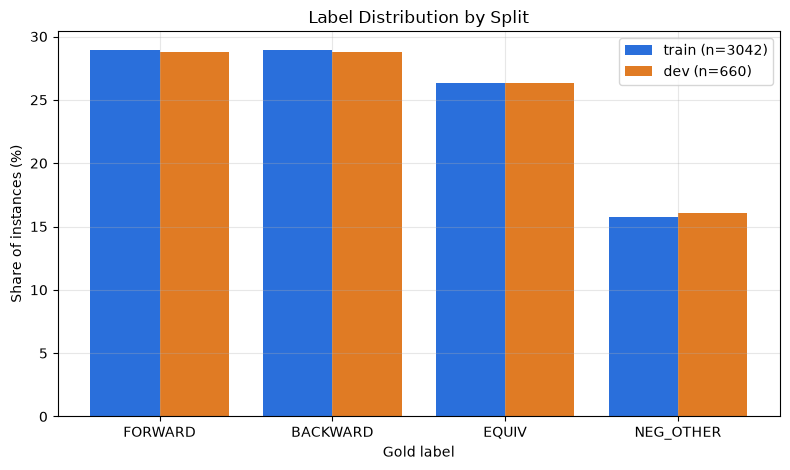

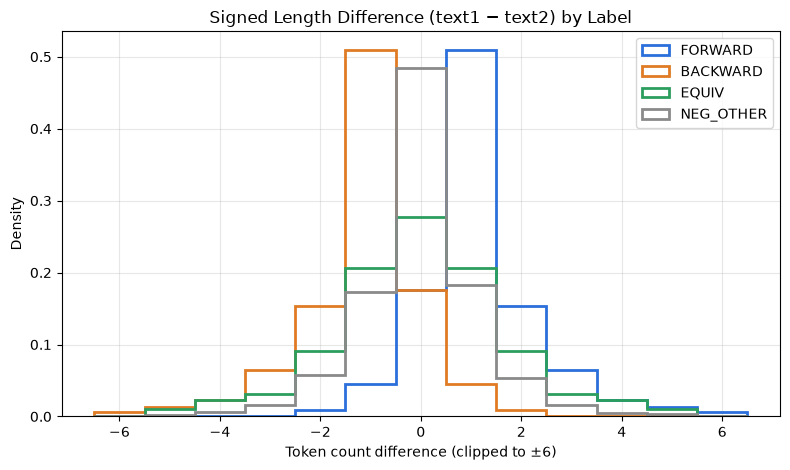

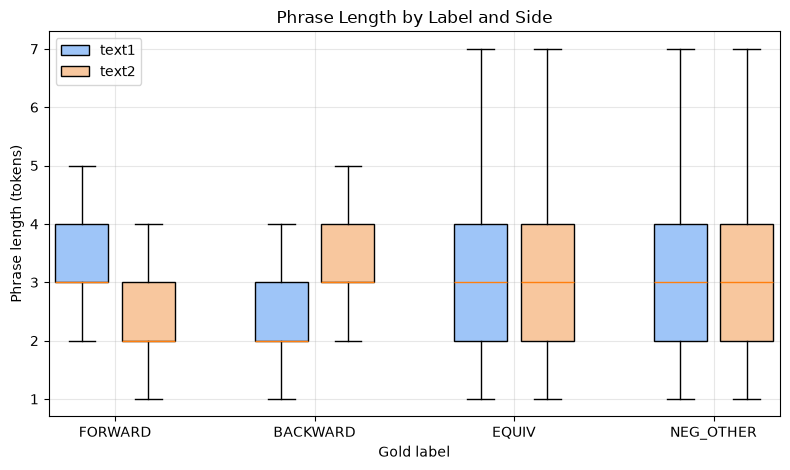

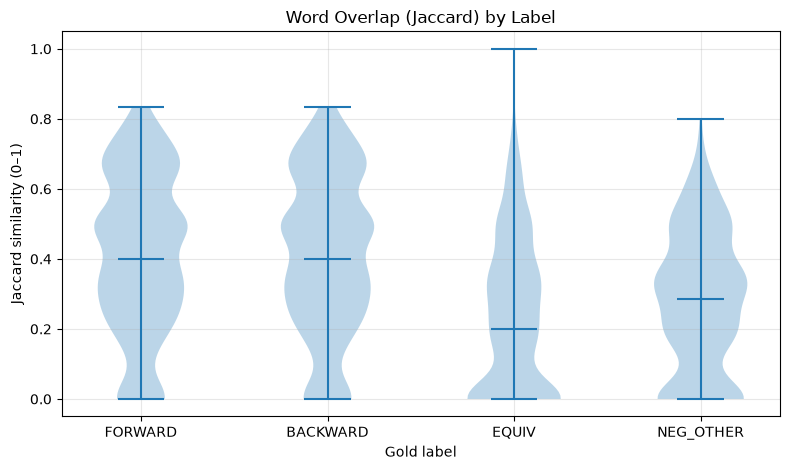

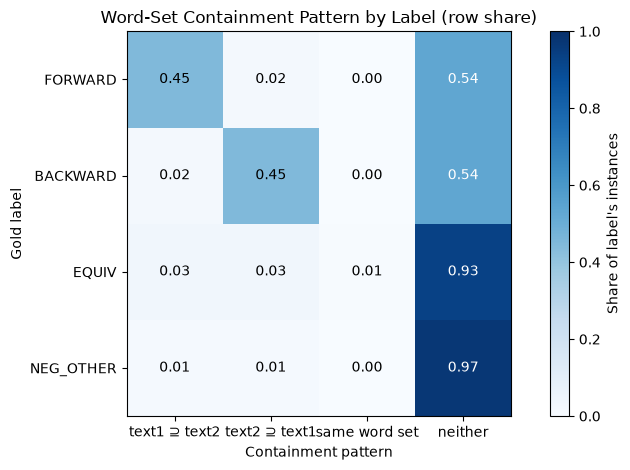

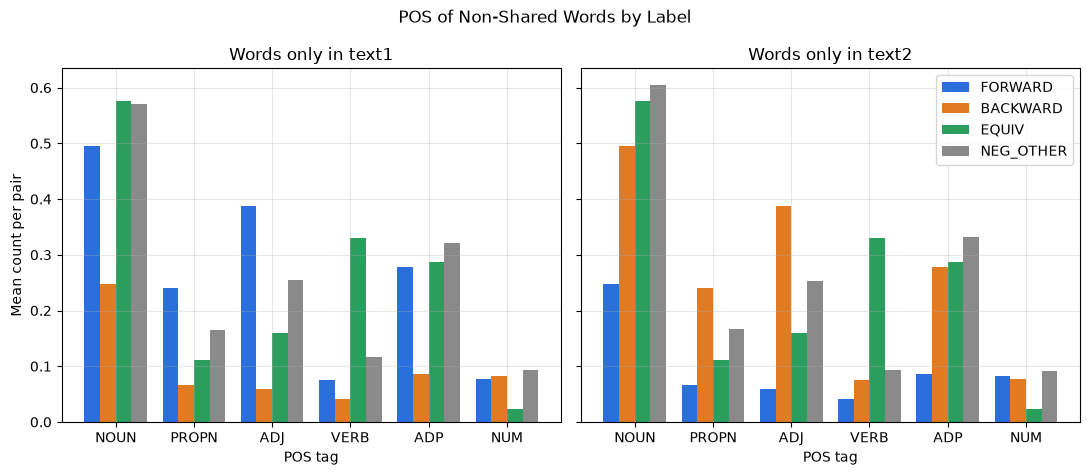

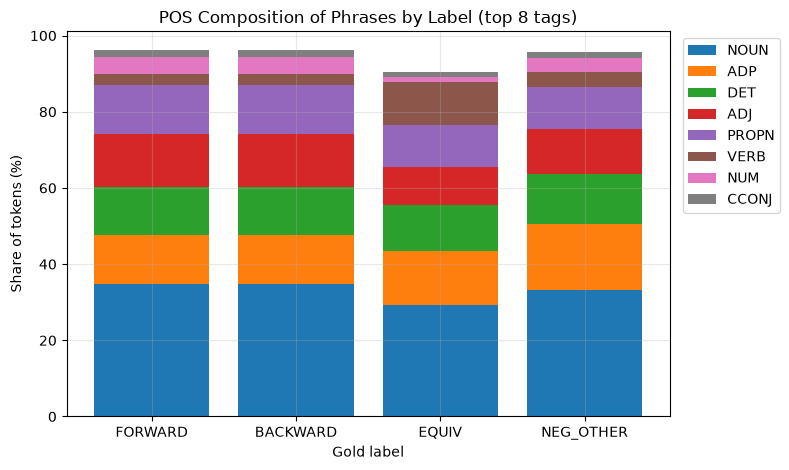

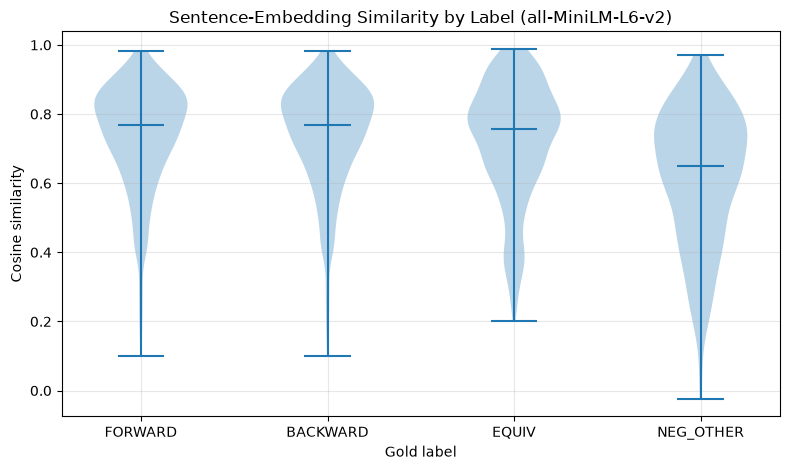

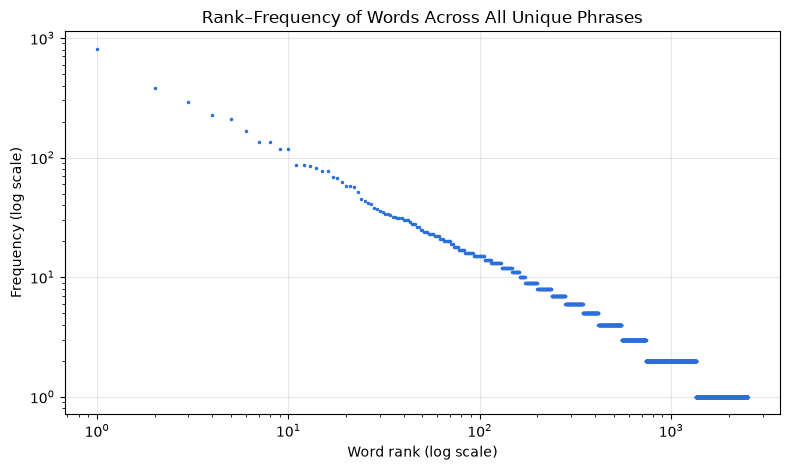

saved results/eda_plots.pdf


In [5]:
pdf = PdfPages(OUT / "eda_plots.pdf")
def done(fig):
    fig.tight_layout(); pdf.savefig(fig); plt.show()

# P1 label distribution
fig, ax = plt.subplots()
tab = pd.crosstab(df.label, df.split, normalize="columns").loc[ORDER] * 100
x = np.arange(4)
ax.bar(x - 0.2, tab["train"], 0.4, label=f"train (n={len(train)})", color="#2a6fdb")
ax.bar(x + 0.2, tab["dev"], 0.4, label=f"dev (n={len(dev)})", color="#e07b24")
ax.set_xticks(x, [SHORT[l] for l in ORDER]); ax.legend()
ax.set(title="Label Distribution by Split", xlabel="Gold label", ylabel="Share of instances (%)")
done(fig)

# P2 signed length difference
fig, ax = plt.subplots()
for lab in ORDER:
    ax.hist(df[df.label == lab].len_diff.clip(-6, 6), bins=np.arange(-6.5, 7.5, 1), histtype="step",
            linewidth=2, density=True, label=SHORT[lab], color=COLORS[lab])
ax.legend()
ax.set(title="Signed Length Difference (text1 − text2) by Label",
       xlabel="Token count difference (clipped to ±6)", ylabel="Density")
done(fig)

# P3 phrase length per side
fig, ax = plt.subplots()
data, pos = [], []
for i, lab in enumerate(ORDER):
    sub = df[df.label == lab]; data += [sub.len1, sub.len2]; pos += [i * 3, i * 3 + 1]
bp = ax.boxplot(data, positions=pos, widths=0.8, patch_artist=True, showfliers=False)
for j, b in enumerate(bp["boxes"]):
    b.set_facecolor("#9ec5f8" if j % 2 == 0 else "#f8c79e")
ax.set_xticks([i * 3 + 0.5 for i in range(4)], [SHORT[l] for l in ORDER])
ax.legend([bp["boxes"][0], bp["boxes"][1]], ["text1", "text2"])
ax.set(title="Phrase Length by Label and Side", xlabel="Gold label", ylabel="Phrase length (tokens)")
done(fig)

# P4 Jaccard
fig, ax = plt.subplots()
ax.violinplot([df[df.label == l].jaccard for l in ORDER], showmedians=True)
ax.set_xticks(range(1, 5), [SHORT[l] for l in ORDER])
ax.set(title="Word Overlap (Jaccard) by Label", xlabel="Gold label", ylabel="Jaccard similarity (0–1)")
done(fig)

# P5 containment
c12, c21 = df.contains_1_in_2.astype(bool), df.contains_2_in_1.astype(bool)
cont = np.select([c12 & c21, c21, c12], ["same word set", "text1 ⊇ text2", "text2 ⊇ text1"], "neither")
ct = pd.crosstab(df.label, cont, normalize="index").loc[ORDER]
ct = ct[[c for c in ["text1 ⊇ text2", "text2 ⊇ text1", "same word set", "neither"] if c in ct]]
fig, ax = plt.subplots()
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=1)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.values[i, j]:.2f}", ha="center", va="center", color="white" if ct.values[i, j] > 0.5 else "black")
ax.set_xticks(range(ct.shape[1]), ct.columns); ax.set_yticks(range(4), [SHORT[l] for l in ORDER]); ax.grid(False)
ax.set(title="Word-Set Containment Pattern by Label (row share)", xlabel="Containment pattern", ylabel="Gold label")
fig.colorbar(im, ax=ax, label="Share of label's instances")
done(fig)

# P6 POS of non-shared words
cols = ["NOUN", "PROPN", "ADJ", "VERB", "ADP", "NUM"]
if "extra1_NOUN" in df:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
    for ax, side in zip(axes, ["1", "2"]):
        m = df.groupby("label")[[f"extra{side}_{c}" for c in cols]].mean().loc[ORDER]
        for k, lab in enumerate(ORDER):
            ax.bar(np.arange(6) + (k - 1.5) * 0.2, m.loc[lab].values, 0.2, label=SHORT[lab], color=COLORS[lab])
        ax.set_xticks(np.arange(6), cols); ax.set(title=f"Words only in text{side}", xlabel="POS tag")
    axes[0].set_ylabel("Mean count per pair"); axes[1].legend()
    fig.suptitle("POS of Non-Shared Words by Label")
    done(fig)

# P7 POS composition
pp = pos_proportions(df)
if pp is not None:
    pp = pp[ORDER]; top = pp.mean(axis=1).sort_values(ascending=False).index[:8]
    fig, ax = plt.subplots(); bottom = np.zeros(4)
    for k, tag in enumerate(top):
        ax.bar([SHORT[l] for l in ORDER], pp.loc[tag].values * 100, bottom=bottom, label=tag, color=plt.get_cmap("tab10")(k))
        bottom += pp.loc[tag].values * 100
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set(title="POS Composition of Phrases by Label (top 8 tags)", xlabel="Gold label", ylabel="Share of tokens (%)")
    done(fig)

# P8 semantic similarity
if "cos" in df:
    fig, ax = plt.subplots()
    ax.violinplot([df[df.label == l].cos.dropna() for l in ORDER], showmedians=True)
    ax.set_xticks(range(1, 5), [SHORT[l] for l in ORDER])
    ax.set(title="Sentence-Embedding Similarity by Label (all-MiniLM-L6-v2)", xlabel="Gold label", ylabel="Cosine similarity")
    done(fig)

# P9 Zipf
f = np.array(sorted(Counter(w for t in uniq(df) for w in tokens(t)).values(), reverse=True))
fig, ax = plt.subplots()
ax.loglog(np.arange(1, len(f) + 1), f, ".", markersize=3, color="#2a6fdb")
ax.set(title="Rank–Frequency of Words Across All Unique Phrases", xlabel="Word rank (log scale)", ylabel="Frequency (log scale)")
done(fig)
pdf.close()
print("saved results/eda_plots.pdf")

## 4. Baseline A: classical ML (official scorer on dev)
- **Majority:** the floor.
- **LR, length only:** probes the length shortcut.
- **LR, symmetric overlap only:** cannot see direction by construction, so it should fail on FORWARD vs BACKWARD.
- **LR, all engineered features:** the interpretable baseline; coefficients are linked back to the EDA.
- **TF-IDF + LR:** `[tfidf(text1) | tfidf(text2)]` keeps the two sides separate, so direction is preserved.
- **TF-IDF + features + LR.**

In [6]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

F_tr = df[df.split == "train"].reset_index(drop=True)
F_dev = df[df.split == "dev"].reset_index(drop=True)
y_tr = F_tr.label
FEATS = list(pair_features(train.head(2)).columns)
LENGTH = ["len1", "len2", "len_diff", "char_diff"]
SYMMETRIC = ["jaccard", "identical"]
results = {}

def run(name, preds):
    path = write_predictions(F_dev.instance_id, preds, OUT / "predictions" / f"{name}.csv")
    results[name] = headline(score(path, "dev", OUT / "scores" / name))
    print(f"{name:26s} " + "  ".join(f"{k}={v:.3f}" for k, v in results[name].items()))

lr = lambda: LogisticRegression(max_iter=5000, random_state=SEED)
run("majority", [y_tr.value_counts().idxmax()] * len(F_dev))
for name, cols_ in [("lr_length_only", LENGTH), ("lr_overlap_only", SYMMETRIC), ("lr_engineered_features", FEATS)]:
    m = make_pipeline(StandardScaler(), lr()).fit(F_tr[cols_], y_tr)
    run(name, m.predict(F_dev[cols_]))
    if name == "lr_engineered_features":
        feat_lr = m

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(pd.concat([F_tr.text1, F_tr.text2]))
tf = lambda d: hstack([vec.transform(d.text1), vec.transform(d.text2)]).tocsr()
X_tr, X_dev = tf(F_tr), tf(F_dev)
run("tfidf_lr", lr().fit(X_tr, y_tr).predict(X_dev))
sc = StandardScaler().fit(F_tr[FEATS])
Xc_tr = hstack([X_tr, csr_matrix(sc.transform(F_tr[FEATS]))]).tocsr()
Xc_dev = hstack([X_dev, csr_matrix(sc.transform(F_dev[FEATS]))]).tocsr()
run("tfidf_plus_features_lr", lr().fit(Xc_tr, y_tr).predict(Xc_dev))

classical = pd.DataFrame(results).T
classical.to_csv(OUT / "classical_results.csv")
classical.round(3)

majority                   weighted_f1=0.129  soft_cons=0.000  hard_cons=0.000  macro_f1=0.112  accuracy=0.288
lr_length_only             weighted_f1=0.464  soft_cons=0.989  hard_cons=0.628  macro_f1=0.408  accuracy=0.532
lr_overlap_only            weighted_f1=0.324  soft_cons=0.368  hard_cons=0.188  macro_f1=0.291  accuracy=0.370
lr_engineered_features     weighted_f1=0.593  soft_cons=0.877  hard_cons=0.653  macro_f1=0.558  accuracy=0.602


tfidf_lr                   weighted_f1=0.484  soft_cons=0.877  hard_cons=0.542  macro_f1=0.452  accuracy=0.500


tfidf_plus_features_lr     weighted_f1=0.620  soft_cons=0.856  hard_cons=0.661  macro_f1=0.588  accuracy=0.626


,weighted_f1,soft_cons,hard_cons,macro_f1,accuracy
majority,0.129,0.000,0.000,0.112,0.288
lr_length_only,0.464,0.989,0.628,0.408,0.532
lr_overlap_only,0.324,0.368,0.188,0.291,0.370
lr_engineered_features,0.593,0.877,0.653,0.558,0.602
tfidf_lr,0.484,0.877,0.542,0.452,0.500
tfidf_plus_features_lr,0.620,0.856,0.661,0.588,0.626


In [7]:
# standardised LR coefficients: comparable across features, link them to the EDA
clf = feat_lr[-1]
coef = pd.DataFrame(clf.coef_.T, index=FEATS, columns=clf.classes_)
coef.to_csv(OUT / "feature_lr_coefficients.csv")
for c in ORDER:
    s = coef[c].sort_values(ascending=False)
    print(f"{SHORT[c]:10s} + {', '.join(s.index[:4])}   |  − {', '.join(s.index[-3:])}")
coef.round(2)

FORWARD    + extra1_PROPN, extra1_NOUN, extra1_ADJ, char_diff   |  − extra2_PROPN, extra2_ADJ, extra2_NOUN
BACKWARD   + len_diff, extra2_PROPN, extra2_NOUN, extra2_ADJ   |  − extra1_PROPN, extra1_ADJ, extra1_NOUN
EQUIV      + extra2, extra1, extra2_VERB, extra1_VERB   |  − extra2_ADJ, extra1_NUM, extra2_NUM
NEG_OTHER  + extra1_ADJ, extra2_ADJ, extra2_ADP, extra2_NOUN   |  − extra2, contains_1_in_2, contains_2_in_1


,BACKWARD_ENTAILMENT,EQUIVALENCE,FORWARD_ENTAILMENT,NEGATIVE_OTHER
len1,0.28,0.07,-0.33,-0.02
len2,-0.35,0.07,0.24,0.05
len_diff,0.59,0.00,-0.53,-0.06
char_diff,-0.44,0.01,0.47,-0.04
jaccard,-0.08,0.18,-0.12,0.02
identical,0.00,0.00,0.00,0.00
cov_1_in_2,0.32,0.04,-0.17,-0.18
cov_2_in_1,-0.28,-0.09,0.25,0.12
contains_1_in_2,0.36,-0.06,0.16,-0.46
contains_2_in_1,0.20,0.02,0.44,-0.65


## 5. Baseline B: pretrained encoders, **full fine-tuning**
Cross-encoder input `[CLS] text1 [SEP] text2 [SEP]` → 4-way classifier head; all weights are updated.
Fixed hyperparameters and a fixed number of epochs, with **no early stopping or tuning on dev**, since dev is our only held-out set.
Device: CUDA on Colab, MPS on Apple Silicon, otherwise CPU.

*Run log (report this honestly):* a first run (4 epochs, lr 2e-5) had two problems: (i) a batching bug dropped BERT's
`token_type_ids`, so the model could not tell text1 from text2 segments; (ii) the training loss was still ~0.8 after 4 epochs
(underfitting, judged on the **training** loss, not dev). DeBERTa-v3 produced NaN losses on MPS. The configuration was
revised once (bug fix, 6 epochs, lr 3e-5, DeBERTa moved to CPU/Colab) and then kept fixed.

In [8]:
if RUN_TRANSFORMERS:
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    DEVICE_DEFAULT = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
    DEVICE = DEVICE_DEFAULT
    print("device:", DEVICE)
    L2I = {l: i for i, l in enumerate(LABELS)}

    def set_seed(s):
        random.seed(s); np.random.seed(s); torch.manual_seed(s)

    def loader(d, tok, shuffle):
        enc = tok(list(d.text1), list(d.text2), truncation=True, max_length=CFG["max_len"])
        y = d.label.map(L2I).tolist()
        keys = [k for k in ("input_ids", "attention_mask", "token_type_ids") if k in enc]  # token_type_ids = text1/text2 segment ids (BERT)
        items = [{**{k: enc[k][i] for k in keys}, "y": y[i]} for i in range(len(d))]
        def collate(b):
            batch = tok.pad([{k: x[k] for k in keys} for x in b], return_tensors="pt")
            batch["labels"] = torch.tensor([x["y"] for x in b])
            return batch
        return DataLoader(items, batch_size=CFG["batch_size"], shuffle=shuffle, collate_fn=collate)

    @torch.no_grad()
    def predict_probs(model, dl):
        model.eval(); out = []
        for b in dl:
            b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
            out.append(torch.softmax(model(**b).logits.float(), -1).cpu())
        return torch.cat(out).numpy()

    def finetune(model_name, seed):
        global DEVICE
        DEVICE = DEVICE_DEFAULT
        if DEVICE == "mps" and "deberta" in model_name.lower():
            DEVICE = "cpu"; print("DeBERTa on Mac: using CPU (MPS gives NaN losses for DeBERTa-v3)")
        set_seed(seed)
        short = model_name.split("/")[-1]
        tok = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(LABELS)).to(DEVICE)
        tr_dl, dv_dl = loader(train, tok, True), loader(dev, tok, False)
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
        total = len(tr_dl) * CFG["epochs"]
        sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * total), total)
        curve = []
        for ep in range(1, CFG["epochs"] + 1):
            model.train(); losses = []; t0 = time.time()
            for b in tr_dl:
                b = {k: v.to(DEVICE) for k, v in b.items()}
                loss = model(**b).loss
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); sch.step(); opt.zero_grad()
                losses.append(loss.item())
                if not np.isfinite(losses[-1]):
                    raise RuntimeError(f"{short}: non-finite training loss on {DEVICE}. Run this model on CPU or Colab.")
            probs = predict_probs(model, dv_dl)
            p = write_predictions(dev.instance_id, [LABELS[i] for i in probs.argmax(1)], OUT / "predictions" / "_epoch_tmp.csv")
            s = headline(score(p, "dev"))
            curve.append({"model": short, "seed": seed, "epoch": ep, "train_loss": float(np.mean(losses)), **s})
            print(f"{short} seed={seed} ep={ep} loss={np.mean(losses):.3f} ({time.time()-t0:.0f}s) " +
                  " ".join(f"{k}={v:.3f}" for k, v in s.items()))
        name = f"{short}_seed{seed}"            # final model = last epoch, fixed in advance
        p = write_predictions(dev.instance_id, [LABELS[i] for i in probs.argmax(1)], OUT / "predictions" / f"{name}.csv")
        s = headline(score(p, "dev", OUT / "scores" / name))
        pd.DataFrame(probs, columns=LABELS).assign(instance_id=dev.instance_id.values).to_csv(
            OUT / "predictions" / f"{name}_probs.csv", index=False)
        del model
        if DEVICE == "cuda": torch.cuda.empty_cache()
        if DEVICE == "mps": torch.mps.empty_cache()
        return {"model": short, "seed": seed, **s}, curve

    finals, curves = [], []
    for m in MODELS:
        for s in SEEDS:
            f, c = finetune(m, s); finals.append(f); curves += c
    (OUT / "predictions" / "_epoch_tmp.csv").unlink(missing_ok=True)
    finals, curves = pd.DataFrame(finals), pd.DataFrame(curves)
    finals.to_csv(OUT / "transformer_results_per_seed.csv", index=False)
    curves.to_csv(OUT / "transformer_training_curves.csv", index=False)
    json.dump({**CFG, "models": MODELS, "seeds": SEEDS}, open(OUT / "transformer_config.json", "w"), indent=2)
    display(finals.round(3))

device: mps


Loading weights:   0%|                                                                           | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|███████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 6694.90it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


bert-base-uncased seed=13 ep=1 loss=1.307 (64s) weighted_f1=0.462 soft_cons=0.693 hard_cons=0.523 macro_f1=0.412 accuracy=0.536


...

roberta-base seed=87 ep=3 loss=0.479 (87s) weighted_f1=0.756 soft_cons=0.801 hard_cons=0.736 macro_f1=0.731 accuracy=0.756


roberta-base seed=87 ep=4 loss=0.297 (86s) weighted_f1=0.745 soft_cons=0.773 hard_cons=0.708 macro_f1=0.722 accuracy=0.741


roberta-base seed=87 ep=5 loss=0.164 (85s) weighted_f1=0.767 soft_cons=0.794 hard_cons=0.740 macro_f1=0.745 accuracy=0.767


roberta-base seed=87 ep=6 loss=0.123 (87s) weighted_f1=0.765 soft_cons=0.798 hard_cons=0.733 macro_f1=0.743 accuracy=0.762


,model,seed,weighted_f1,soft_cons,hard_cons,macro_f1,accuracy
0,bert-base-uncased,13,0.702,0.755,0.686,0.674,0.702
1,bert-base-uncased,42,0.677,0.773,0.671,0.653,0.685
2,bert-base-uncased,87,0.734,0.794,0.722,0.712,0.733
3,roberta-base,13,0.766,0.819,0.747,0.743,0.767
4,roberta-base,42,0.763,0.794,0.736,0.740,0.758
5,roberta-base,87,0.765,0.798,0.733,0.743,0.762


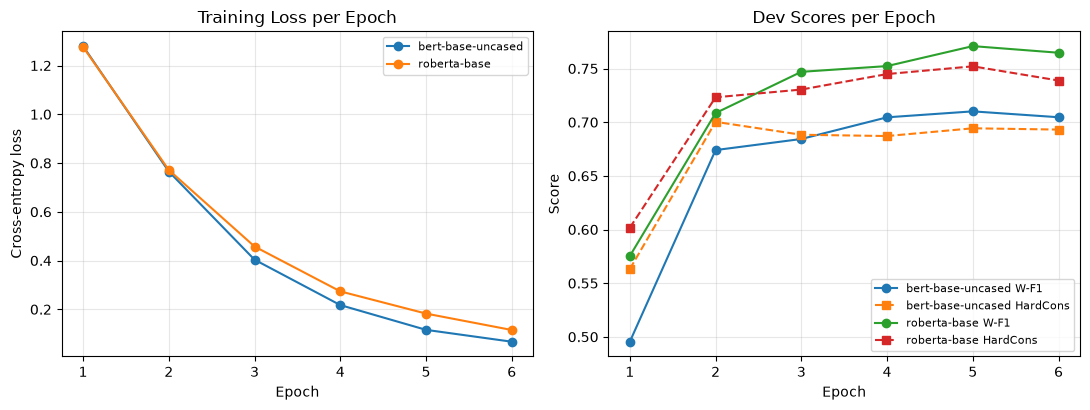

In [9]:
# training curves: train loss and dev W-F1 per epoch (diagnostic only, not used for model selection)
tc = OUT / "transformer_training_curves.csv"
if tc.exists():
    cv = pd.read_csv(tc).groupby(["model", "epoch"])[["train_loss", "weighted_f1", "hard_cons"]].mean().reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for m, g in cv.groupby("model"):
        axes[0].plot(g.epoch, g.train_loss, marker="o", label=m)
        axes[1].plot(g.epoch, g.weighted_f1, marker="o", label=f"{m} W-F1")
        axes[1].plot(g.epoch, g.hard_cons, marker="s", linestyle="--", label=f"{m} HardCons")
    axes[0].set(title="Training Loss per Epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(title="Dev Scores per Epoch", xlabel="Epoch", ylabel="Score")
    for a in axes: a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUT / "training_curves.pdf"); plt.show()

## 6. Results table (official metrics on dev)
SoftCons only checks that the two directions are *compatible*, not correct, so a trivial model can score high
(see the length-only LR). HardCons requires both directions to be correct.

In [10]:
NAMES = {"majority": "Majority class", "lr_length_only": "LR (length only)", "lr_overlap_only": "LR (symmetric overlap only)",
         "lr_engineered_features": "LR (engineered features)", "tfidf_lr": "TF-IDF + LR", "tfidf_plus_features_lr": "TF-IDF + features + LR"}
MET = ["weighted_f1", "soft_cons", "hard_cons", "macro_f1", "accuracy"]
rows = [{"group": "Classical (A)", "model": NAMES[k], **{c: f"{r[c]:.3f}" for c in MET}} for k, r in classical.iterrows()]
pt = OUT / "transformer_results_per_seed.csv"
if pt.exists():
    for m, g in pd.read_csv(pt).groupby("model"):
        cell = (lambda c: f"{g[c].mean():.3f} $\\pm$ {g[c].std(ddof=0):.3f}") if len(g) > 1 else (lambda c: f"{g[c].mean():.3f}")
        rows.append({"group": "Pretrained, fine-tuned (B)", "model": f"{m} ({len(g)} seed{'s' if len(g) > 1 else ''})", **{c: cell(c) for c in MET}})
table = pd.DataFrame(rows)
table.to_csv(OUT / "all_results.csv", index=False)

lines = [r"\begin{table}[t]", r"\centering", r"\small", r"\begin{tabular}{lccccc}", r"\toprule",
         r"Model & W-F1 & SoftCons & HardCons & Macro-F1 & Acc. \\", r"\midrule"]
for g, sub in table.groupby("group", sort=False):
    lines.append(rf"\multicolumn{{6}}{{l}}{{\textit{{{g}}}}} \\")
    lines += [" & ".join([r.model.replace("_", r"\_")] + [r[c] for c in MET]) + r" \\" for _, r in sub.iterrows()]
lines += [r"\bottomrule", r"\end{tabular}",
          r"\caption{Dev results (Track 1, English), official scorer. W-F1, SoftCons and HardCons are the official metrics.}",
          r"\label{tab:results}", r"\end{table}"]
(OUT / "results_table.tex").write_text("\n".join(lines) + "\n")
table

,group,model,weighted_f1,soft_cons,hard_cons,macro_f1,accuracy
0,Classical (A),Majority class,0.129,0.000,0.000,0.112,0.288
1,Classical (A),LR (length only),0.464,0.989,0.628,0.408,0.532
2,Classical (A),LR (symmetric overlap only),0.324,0.368,0.188,0.291,0.370
3,Classical (A),LR (engineered features),0.593,0.877,0.653,0.558,0.602
4,Classical (A),TF-IDF + LR,0.484,0.877,0.542,0.452,0.500
5,Classical (A),TF-IDF + features + LR,0.620,0.856,0.661,0.588,0.626
6,"Pretrained, fine-tuned (B)",bert-base-uncased (3 seeds),0.705 $\pm$ 0.023,0.774 $\pm$ 0.016,0.693 $\pm$ 0.021,0.680 $\pm$ 0.024,0.707 $\pm$ 0.020
7,"Pretrained, fine-tuned (B)",roberta-base (3 seeds),0.765 $\pm$ 0.002,0.804 $\pm$ 0.011,0.739 $\pm$ 0.006,0.742 $\pm$ 0.002,0.762 $\pm$ 0.004


## 7. Error analysis
For the best classical model and each fine-tuned model (seed 42):
- confusion matrix
- **pair-level outcomes** on reversible pairs: both directions correct / consistent but wrong / direction-blind / one direction NEG_OTHER
- heuristic error types, plus 5 sampled errors per type for manual reading (`errors_sample.csv`)

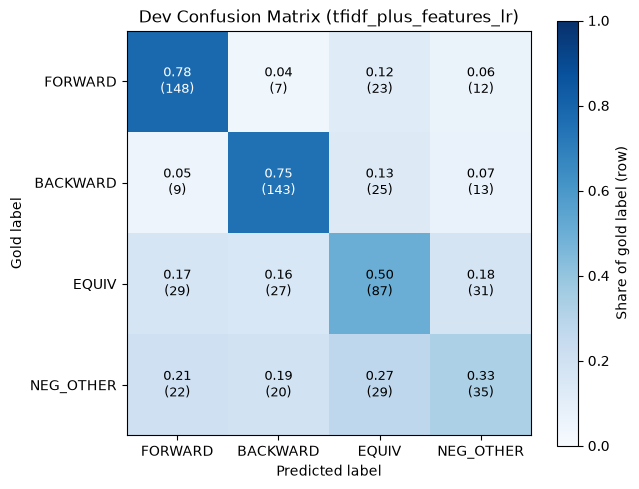

Model: tfidf_plus_features_lr   dev accuracy 0.626

Confusion matrix (rows = gold):
pred                 FORWARD_ENTAILMENT  BACKWARD_ENTAILMENT  EQUIVALENCE  NEGATIVE_OTHER
label                                                                                    
FORWARD_ENTAILMENT                  148                    7           23              12
BACKWARD_ENTAILMENT                   9                  143           25              13
EQUIVALENCE                          29                   27           87              31
NEGATIVE_OTHER                       22                   20           29              35

Reversible-pair outcomes:
pair type                               EQUIV pair  FWD/BWD pair  All
outcome                                                              
both directions correct                         40           143  183
consistent but wrong                            25            29   54
direction-blind (same label both ways)           2             2    4

,text1,text2,label,pred,error_type
273,over police violence,over police crackdown,EQUIVALENCE,BACKWARD_ENTAILMENT,EQUIV vs entailment confusion
451,into strategic rebelheld town,on rebel-held town,FORWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
252,Two French journalists,2 French Journalists,EQUIVALENCE,FORWARD_ENTAILMENT,EQUIV vs entailment confusion
442,for another term,for seventh term,BACKWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
182,The wall-mounted flat-screen TV,of a television screen,FORWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
343,a monochrome photograph,a black and white photo,EQUIVALENCE,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
589,as Manager,Ferguson,NEGATIVE_OTHER,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)
634,A red double decker bus,A white bus,NEGATIVE_OTHER,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)
431,Saudis,Saudi Women,FORWARD_ENTAILMENT,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
571,for Mali Town,Mali army,NEGATIVE_OTHER,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)


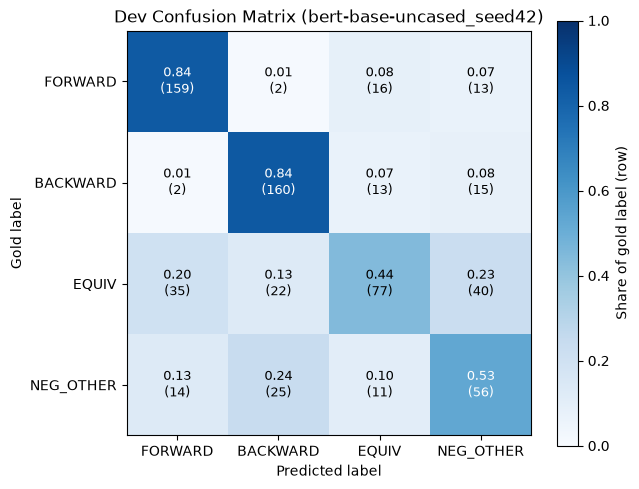

Model: bert-base-uncased_seed42   dev accuracy 0.685

Confusion matrix (rows = gold):
pred                 FORWARD_ENTAILMENT  BACKWARD_ENTAILMENT  EQUIVALENCE  NEGATIVE_OTHER
label                                                                                    
FORWARD_ENTAILMENT                  159                    2           16              13
BACKWARD_ENTAILMENT                   2                  160           13              15
EQUIVALENCE                          35                   22           77              40
NEGATIVE_OTHER                       14                   25           11              56

Reversible-pair outcomes:
pair type                               EQUIV pair  FWD/BWD pair  All
outcome                                                              
both directions correct                         35           151  186
consistent but wrong                            19             9   28
direction-blind (same label both ways)           4             0   

,text1,text2,label,pred,error_type
112,after Zimmerman,George Zimmerman,FORWARD_ENTAILMENT,BACKWARD_ENTAILMENT,EQUIV vs entailment confusion
272,over police crackdown,over police violence,EQUIVALENCE,FORWARD_ENTAILMENT,EQUIV vs entailment confusion
33,as his security adviser,as national security adviser,BACKWARD_ENTAILMENT,FORWARD_ENTAILMENT,EQUIV vs entailment confusion
277,as rupee collapse,as rupee crisis,EQUIVALENCE,BACKWARD_ENTAILMENT,EQUIV vs entailment confusion
284,after pro-Morsi protest,to pro-Morsi protests,EQUIVALENCE,BACKWARD_ENTAILMENT,EQUIV vs entailment confusion
292,May Housing,Housing in May,EQUIVALENCE,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
611,airline pilots,2 Turkish Airlines pilots,NEGATIVE_OTHER,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
645,one,as one,NEGATIVE_OTHER,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
319,their tires,the tires belonging to them,EQUIVALENCE,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
333,a heap,Pile,EQUIVALENCE,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)


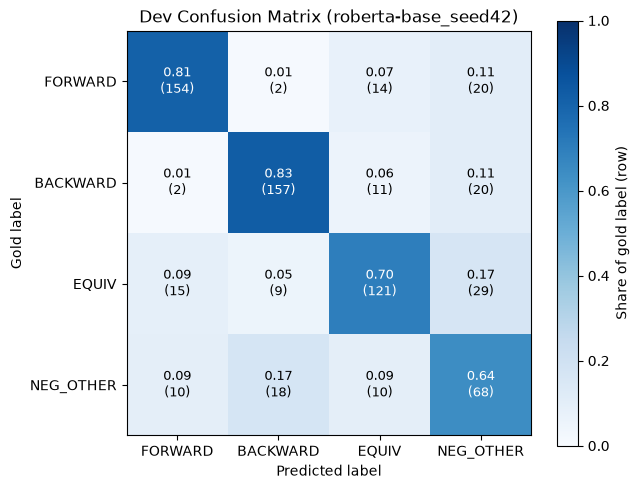

Model: roberta-base_seed42   dev accuracy 0.758

Confusion matrix (rows = gold):
pred                 FORWARD_ENTAILMENT  BACKWARD_ENTAILMENT  EQUIVALENCE  NEGATIVE_OTHER
label                                                                                    
FORWARD_ENTAILMENT                  154                    2           14              20
BACKWARD_ENTAILMENT                   2                  157           11              20
EQUIVALENCE                          15                    9          121              29
NEGATIVE_OTHER                       10                   18           10              68

Reversible-pair outcomes:
pair type                          EQUIV pair  FWD/BWD pair  All
outcome                                                         
both directions correct                    53           151  204
consistent but wrong                        6            10   16
one direction predicted NEG_OTHER          19            23   42
other inconsistency        

,text1,text2,label,pred,error_type
474,closes,abruptly closes,BACKWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
412,Two Asian men and a woman,Two Asian men and Asian woman,BACKWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
515,Several people,People,FORWARD_ENTAILMENT,BACKWARD_ENTAILMENT,EQUIV vs entailment confusion
136,A black car,A black vehicle,FORWARD_ENTAILMENT,EQUIVALENCE,EQUIV vs entailment confusion
326,on green grass,on a lawn,EQUIVALENCE,FORWARD_ENTAILMENT,EQUIV vs entailment confusion
321,along a city path,on the street,EQUIVALENCE,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)
251,ill,fall sick,EQUIVALENCE,BACKWARD_ENTAILMENT,followed length cue (longer side -> entails)
580,in Canada Oil Train Explosion,in Canada train crash,NEGATIVE_OTHER,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)
200,Rabbi Ovadia Yosef,Ovadia Yosef,EQUIVALENCE,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)
573,two people,2,NEGATIVE_OTHER,FORWARD_ENTAILMENT,followed length cue (longer side -> entails)


In [11]:
def analyse(pred_path):
    name = Path(pred_path).stem
    out = OUT / "error_analysis" / name; out.mkdir(parents=True, exist_ok=True)
    d = F_dev.merge(pd.read_csv(pred_path).rename(columns={"label": "pred"}), on="instance_id")
    d["correct"] = d.label == d.pred
    log = [f"Model: {name}   dev accuracy {d.correct.mean():.3f}"]

    cm = pd.crosstab(d.label, d.pred).reindex(index=ORDER, columns=ORDER, fill_value=0)
    cmn = cm.div(cm.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    im = ax.imshow(cmn.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cmn.values[i, j]:.2f}\n({cm.values[i, j]})", ha="center", va="center",
                    color="white" if cmn.values[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(4), [SHORT[l] for l in ORDER]); ax.set_yticks(range(4), [SHORT[l] for l in ORDER]); ax.grid(False)
    ax.set(title=f"Dev Confusion Matrix ({name})", xlabel="Predicted label", ylabel="Gold label")
    fig.colorbar(im, ax=ax, label="Share of gold label (row)")
    fig.tight_layout(); fig.savefig(out / "confusion.pdf"); plt.show()
    log += ["\nConfusion matrix (rows = gold):", cm.to_string()]

    rev = d[d.reverse_pair_id != ""].set_index("instance_id")
    seen, cats = set(), []
    for iid, r in rev.iterrows():
        if iid in seen: continue
        o = rev.loc[r.reverse_pair_id]; seen |= {iid, r.reverse_pair_id}
        p1, p2 = r.pred, o.pred
        if p1 == r.label and p2 == o.label: c = "both directions correct"
        elif p1 in REVERSE and p2 == REVERSE[p1]: c = "consistent but wrong"
        elif p1 == p2 and p1 in ("FORWARD_ENTAILMENT", "BACKWARD_ENTAILMENT"): c = "direction-blind (same label both ways)"
        elif "NEGATIVE_OTHER" in (p1, p2): c = "one direction predicted NEG_OTHER"
        else: c = "other inconsistency"
        cats.append({"pair type": "EQUIV pair" if r.label == "EQUIVALENCE" else "FWD/BWD pair", "outcome": c})
    cats = pd.DataFrame(cats)
    log += ["\nReversible-pair outcomes:", pd.crosstab(cats.outcome, cats["pair type"], margins=True).to_string()]

    err = d[~d.correct].copy()
    ENT = ("FORWARD_ENTAILMENT", "BACKWARD_ENTAILMENT")
    def tag(r):
        if r.pred in ENT and r.len_diff != 0 and ((r.pred == ENT[0]) == (r.len_diff > 0)):
            return "followed length cue (longer side -> entails)"
        if {r.label, r.pred} <= {"EQUIVALENCE", *ENT}: return "EQUIV vs entailment confusion"
        if r.label == "NEGATIVE_OTHER":
            return "unrelated/contrastive predicted as related" + (" (high overlap)" if r.jaccard >= 0.3 else "")
        if r.pred == "NEGATIVE_OTHER": return "related pair rejected as NEG_OTHER"
        return "other"
    err["error_type"] = err.apply(tag, axis=1)
    log += ["\nError types (heuristic tags):", err.error_type.value_counts().to_string()]
    sample = err.sample(frac=1, random_state=0).groupby("error_type").head(5).sort_values("error_type")
    sample[["instance_id", "text1", "text2", "label", "pred", "len_diff", "jaccard", "error_type"]].to_csv(out / "errors_sample.csv", index=False)
    (out / "summary.txt").write_text("\n".join(log) + "\n")
    print("\n".join(log))
    return sample

cands = ["tfidf_plus_features_lr"] + [f"{m.split('/')[-1]}_seed42" for m in MODELS]
for c in cands:
    p = OUT / "predictions" / f"{c}.csv"
    if p.exists():
        print("=" * 80)
        display(analyse(p)[["text1", "text2", "label", "pred", "error_type"]].head(12))

## 8. Notes for the report
- **Discussion:** compare classical vs fine-tuned models on HardCons, not just W-F1, and check whether the fine-tuned models still follow the length cue.
- **Next steps:** enforce consistency at inference (score both directions jointly, e.g. average P(FWD | a,b) with P(BWD | b,a)), augment training with the reversal mapping, and use class-weighting or calibration for NEGATIVE_OTHER.